In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
plt.rcParams["figure.dpi"] = 300
from pathlib import Path

In [2]:
# Base path containing the merged comparison datasets
base = Path("/gws/ssde/j25b/swift/mendrika/asnie/paper")

# Paths for each storm-object comparison with LI
path_core_li = base / "core-vs-li"
path_ts_li = base / "ts-vs-li"


# Load Core vs LI
core_li = pd.read_parquet(path_core_li / "core.parquet")
li_core = pd.read_parquet(path_core_li / "li.parquet")


# Load DWD-TS vs LI
ts_li = pd.read_parquet(path_ts_li / "ts.parquet")
li_ts = pd.read_parquet(path_ts_li / "li.parquet")


# Print dataset sizes
print("Core vs LI:", len(core_li), len(li_core))
print("DWD-TS vs LI:", len(ts_li), len(li_ts))

Core vs LI: 698461 2059726
DWD-TS vs LI: 4148892 5950460


In [4]:
print("Core vs LI thresholds:", sorted(core_li["threshold"].unique()))
print("LI vs Core thresholds:", sorted(li_core["threshold"].unique()))

print("DWD-TS vs LI thresholds:", sorted(ts_li["threshold"].unique()))
print("LI vs DWD-TS thresholds:", sorted(li_ts["threshold"].unique()))

Core vs LI thresholds: [0.0, 0.032, 1.056]
LI vs Core thresholds: [0.0, 0.032, 1.056]
DWD-TS vs LI thresholds: [0.0, 0.032, 1.056]
LI vs DWD-TS thresholds: [0.0, 0.032, 1.056]


In [3]:
def latlon_to_xy_km(lat, lon):
    """
    Convert latitude and longitude coordinates to approximate Cartesian
    coordinates in kilometres using an equirectangular projection.

    A single reference latitude, defined as the mean latitude of all supplied
    points, is used to scale the longitude coordinate. This ensures that the
    same longitude scaling is applied to every point in the dataset.

    Parameters
    ----------
    lat : array-like
        Latitudes in degrees.
    lon : array-like
        Longitudes in degrees.

    Returns
    -------
    xy : ndarray of shape (N, 2)
        Cartesian coordinates in kilometres, with columns corresponding
        to x (east-west) and y (north-south).
    """

    R = 6371.0

    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)

    # Use one reference latitude for consistent longitude scaling
    lat_ref = np.mean(lat_rad)

    x = R * lon_rad * np.cos(lat_ref)
    y = R * lat_rad

    return np.column_stack((x, y))

In [5]:
def object_to_reference_distances(
    df_object,
    df_reference,
    start_hour=12,
    end_hour=21,
):
    """
    Compute the distance from each storm object to the nearest reference object
    at the same timestep, restricted to convectively active hours.

    The reference dataset can be a rainfall product such as RoA or CRR,
    or a lightning product such as LI.
    """

    matches = []

    # Restrict both datasets to the selected hours
    object_active = df_object[
        (df_object["timestamp"].dt.hour >= start_hour)
        & (df_object["timestamp"].dt.hour <= end_hour)
    ]

    reference_active = df_reference[
        (df_reference["timestamp"].dt.hour >= start_hour)
        & (df_reference["timestamp"].dt.hour <= end_hour)
    ]

    # Compare storm objects only with reference objects from the same timestamp
    for t, object_group in object_active.groupby("timestamp"):

        reference_group = reference_active[
            reference_active["timestamp"] == t
        ]

        if len(reference_group) == 0:
            continue

        # Convert reference-object centroids to Cartesian coordinates
        reference_xy = latlon_to_xy_km(
            reference_group["lat_centroid"].values,
            reference_group["lon_centroid"].values,
        )

        tree = cKDTree(reference_xy)

        # Convert storm-object centroids to Cartesian coordinates
        object_xy = latlon_to_xy_km(
            object_group["lat_centroid"].values,
            object_group["lon_centroid"].values,
        )

        # Find the nearest reference object for each storm object
        distances, _ = tree.query(object_xy, k=1)

        matches.extend(distances)

    return np.array(matches)

In [7]:
domains = ["CA", "EA", "SA", "WA"]

thresholds = [0.0, 0.032, 1.056]

distances_li = {}

for domain in domains:
    distances_li[domain] = {}

    for threshold in thresholds:

        core_domain = core_li[
            (core_li["domain"] == domain)
            & (core_li["threshold"] == threshold)
        ]

        li_core_domain = li_core[
            (li_core["domain"] == domain)
            & (li_core["threshold"] == threshold)
        ]

        ts_domain = ts_li[
            (ts_li["domain"] == domain)
            & (ts_li["threshold"] == threshold)
        ]

        li_ts_domain = li_ts[
            (li_ts["domain"] == domain)
            & (li_ts["threshold"] == threshold)
        ]

        distances_li[domain][threshold] = {
            "core": object_to_reference_distances(
                core_domain, li_core_domain
            ),
            "ts": object_to_reference_distances(
                ts_domain, li_ts_domain
            ),
        }

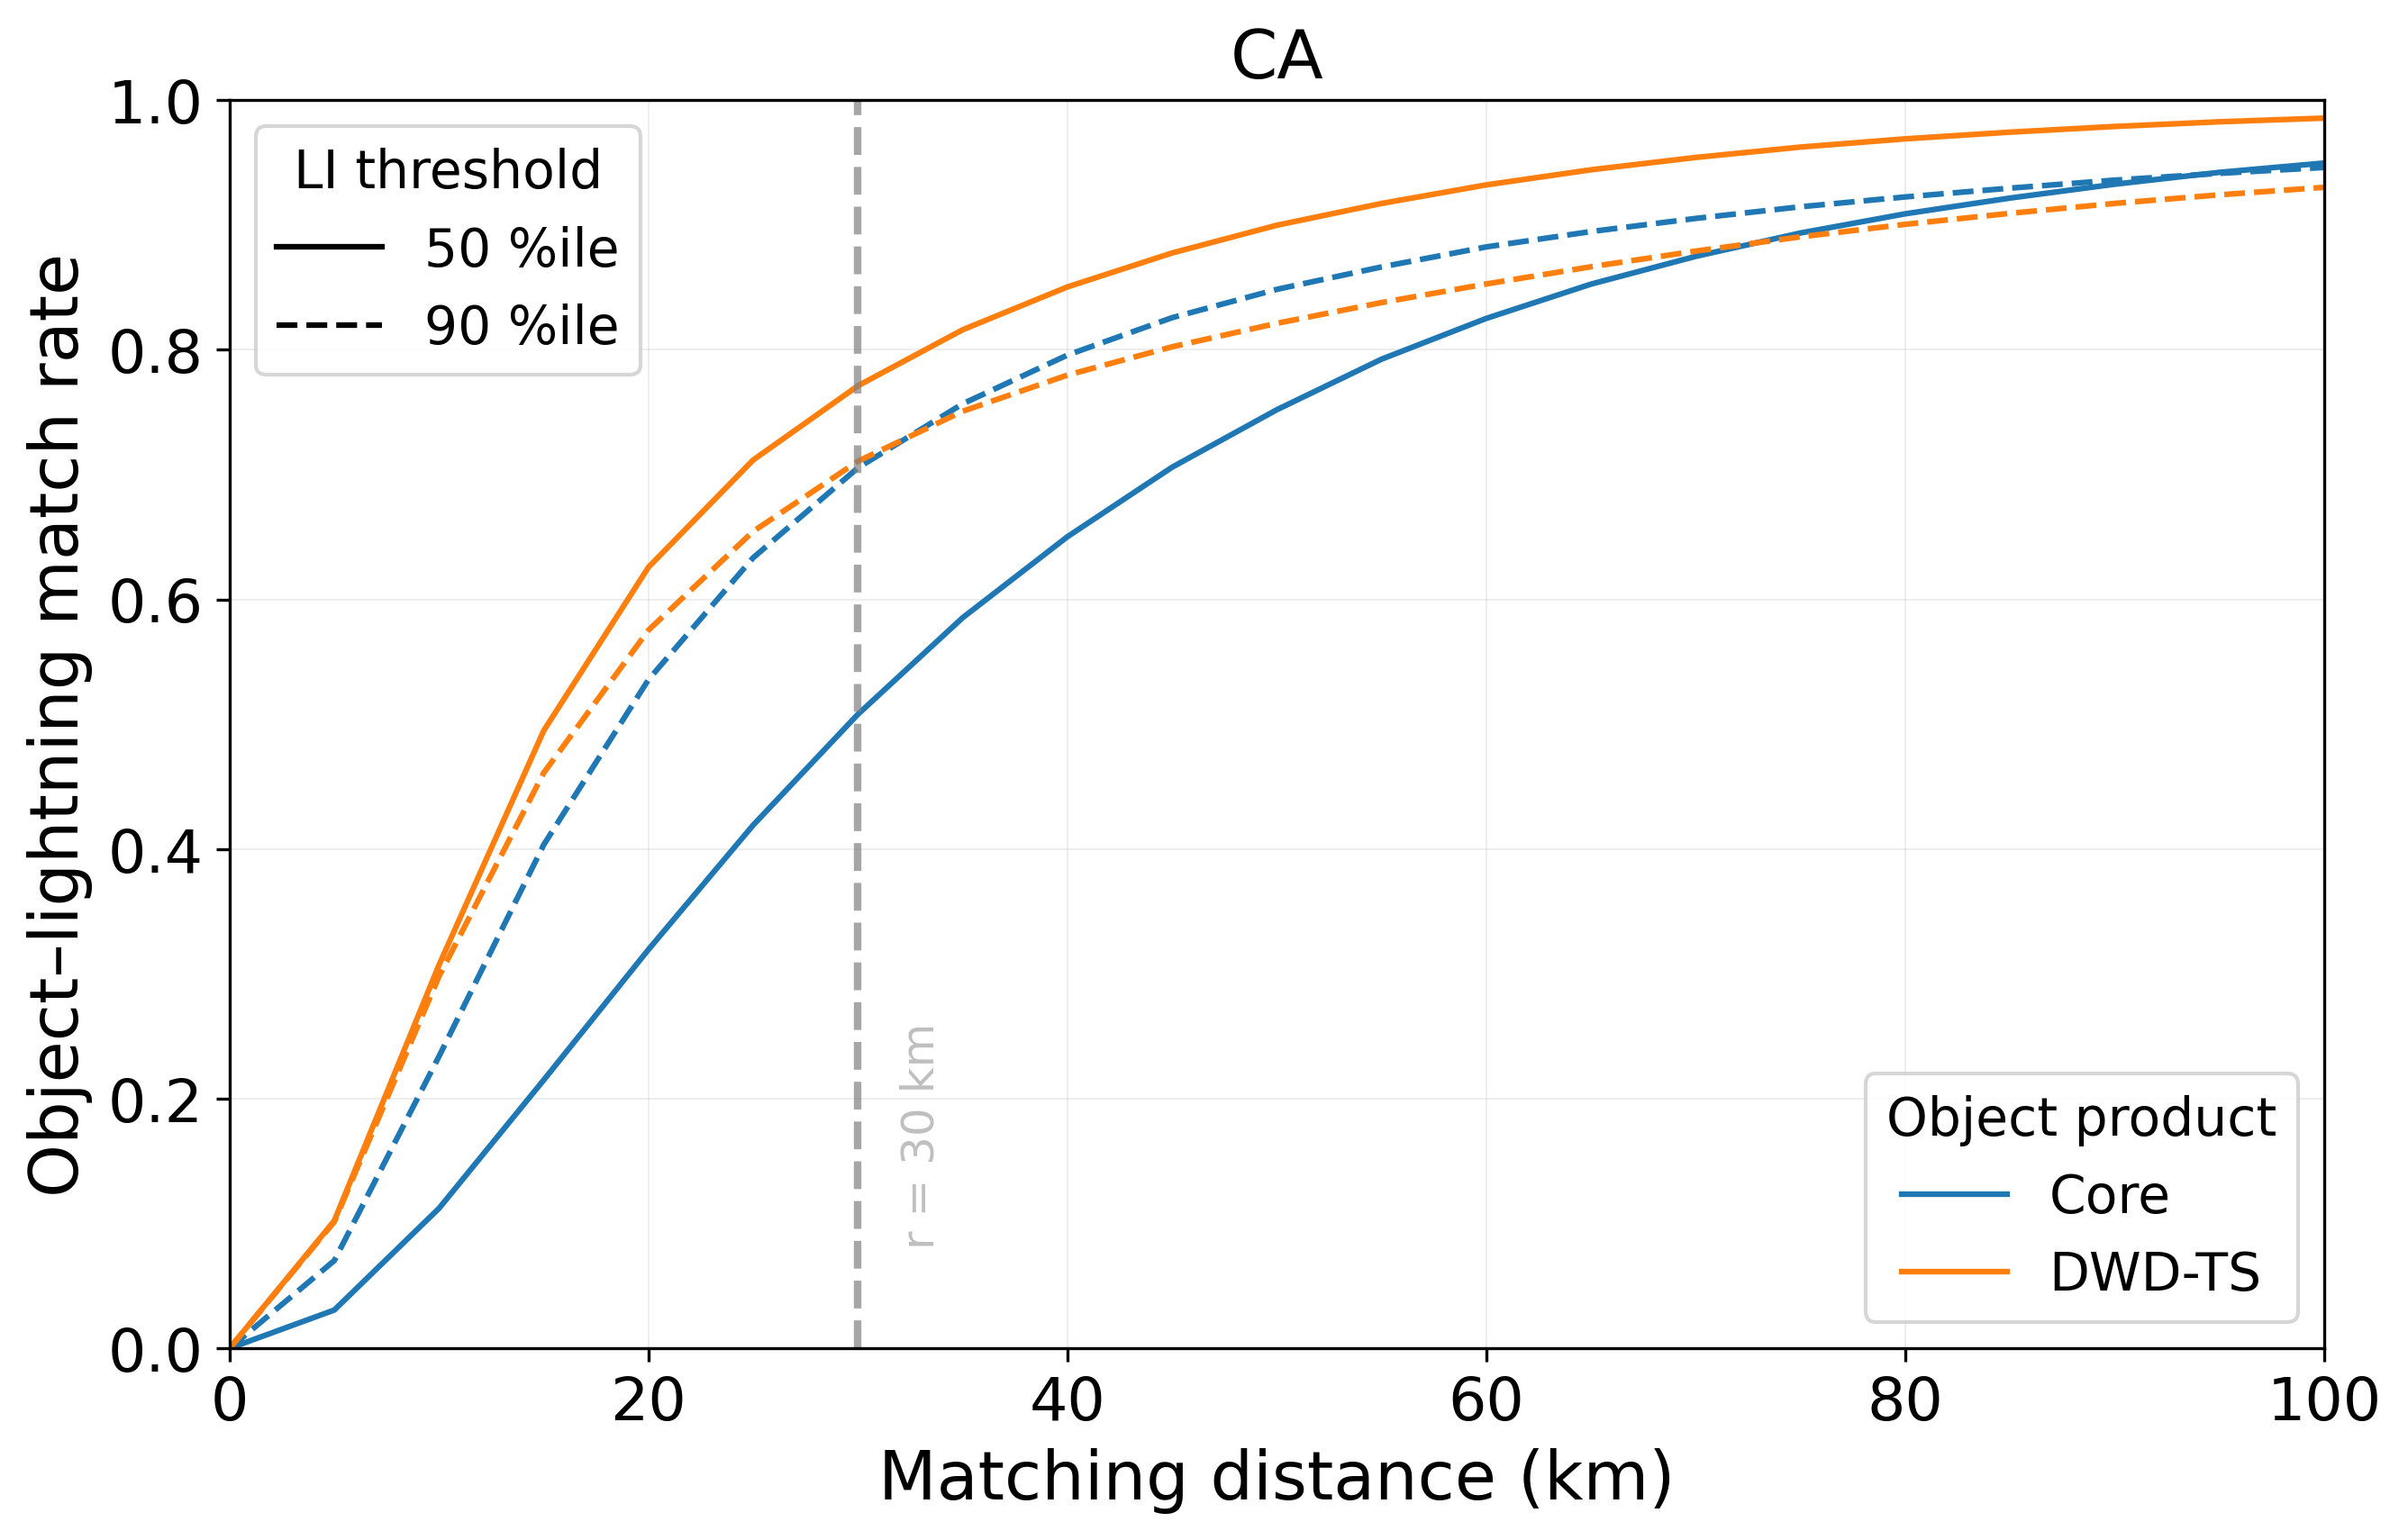

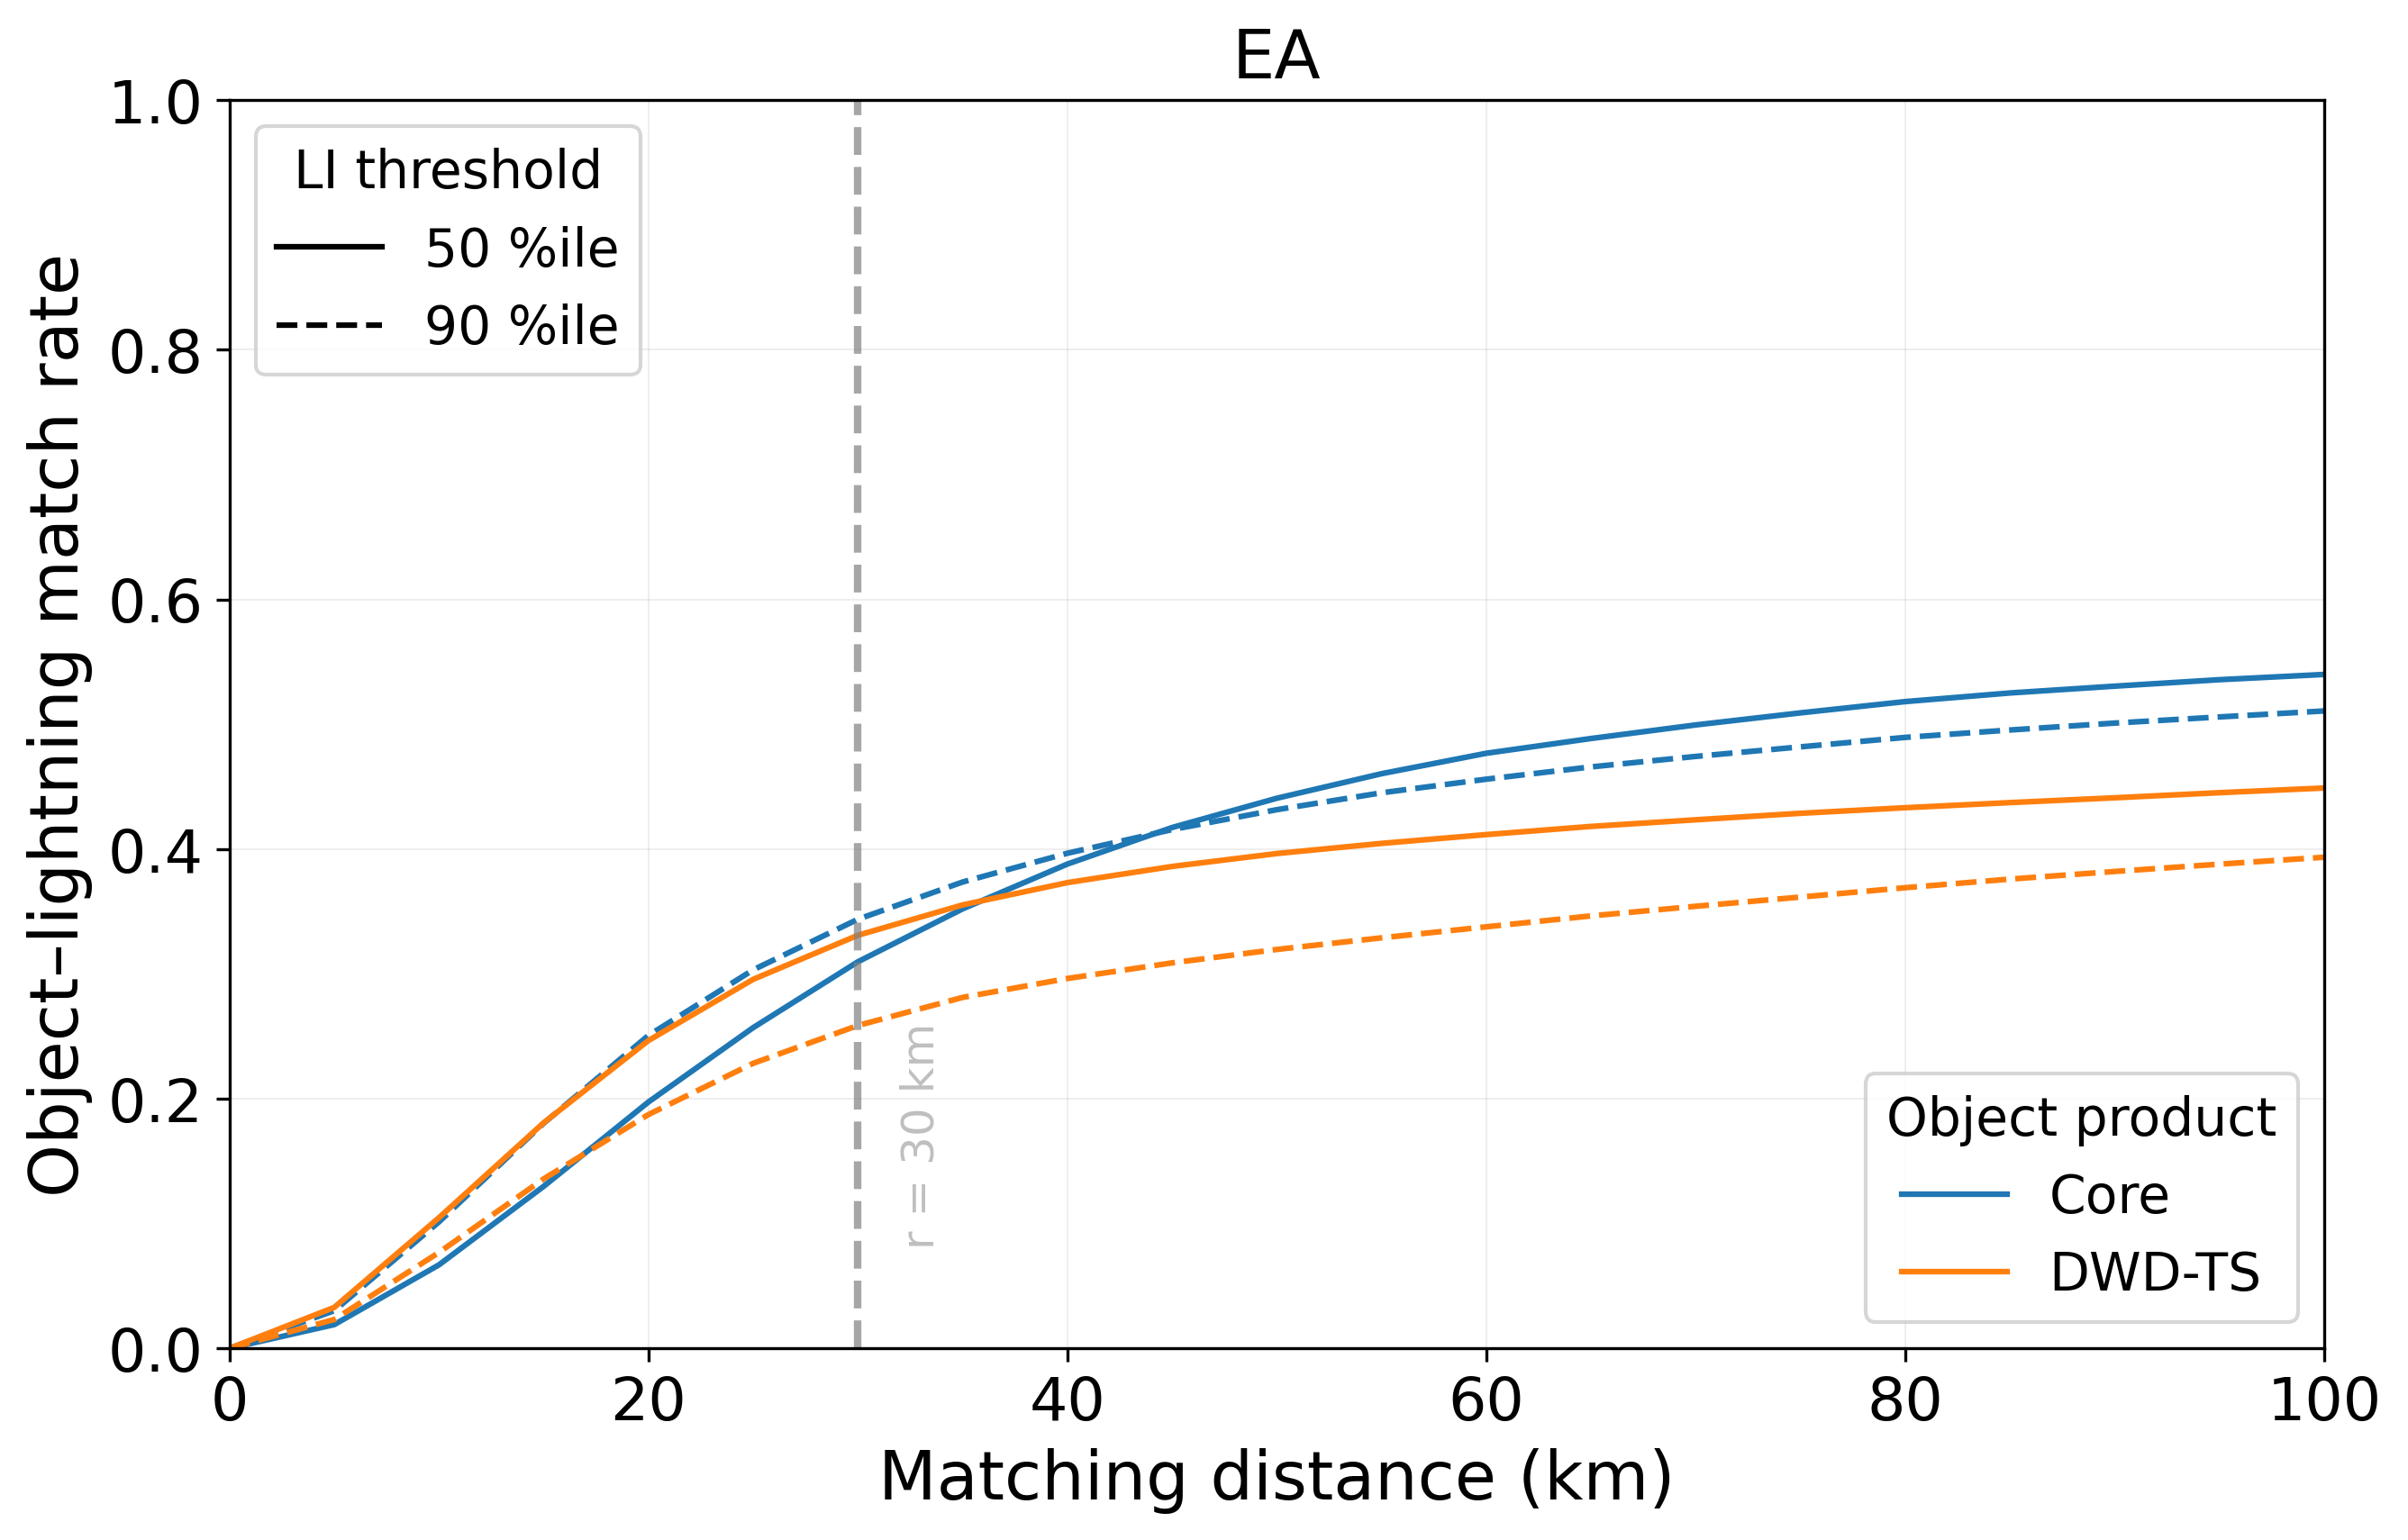

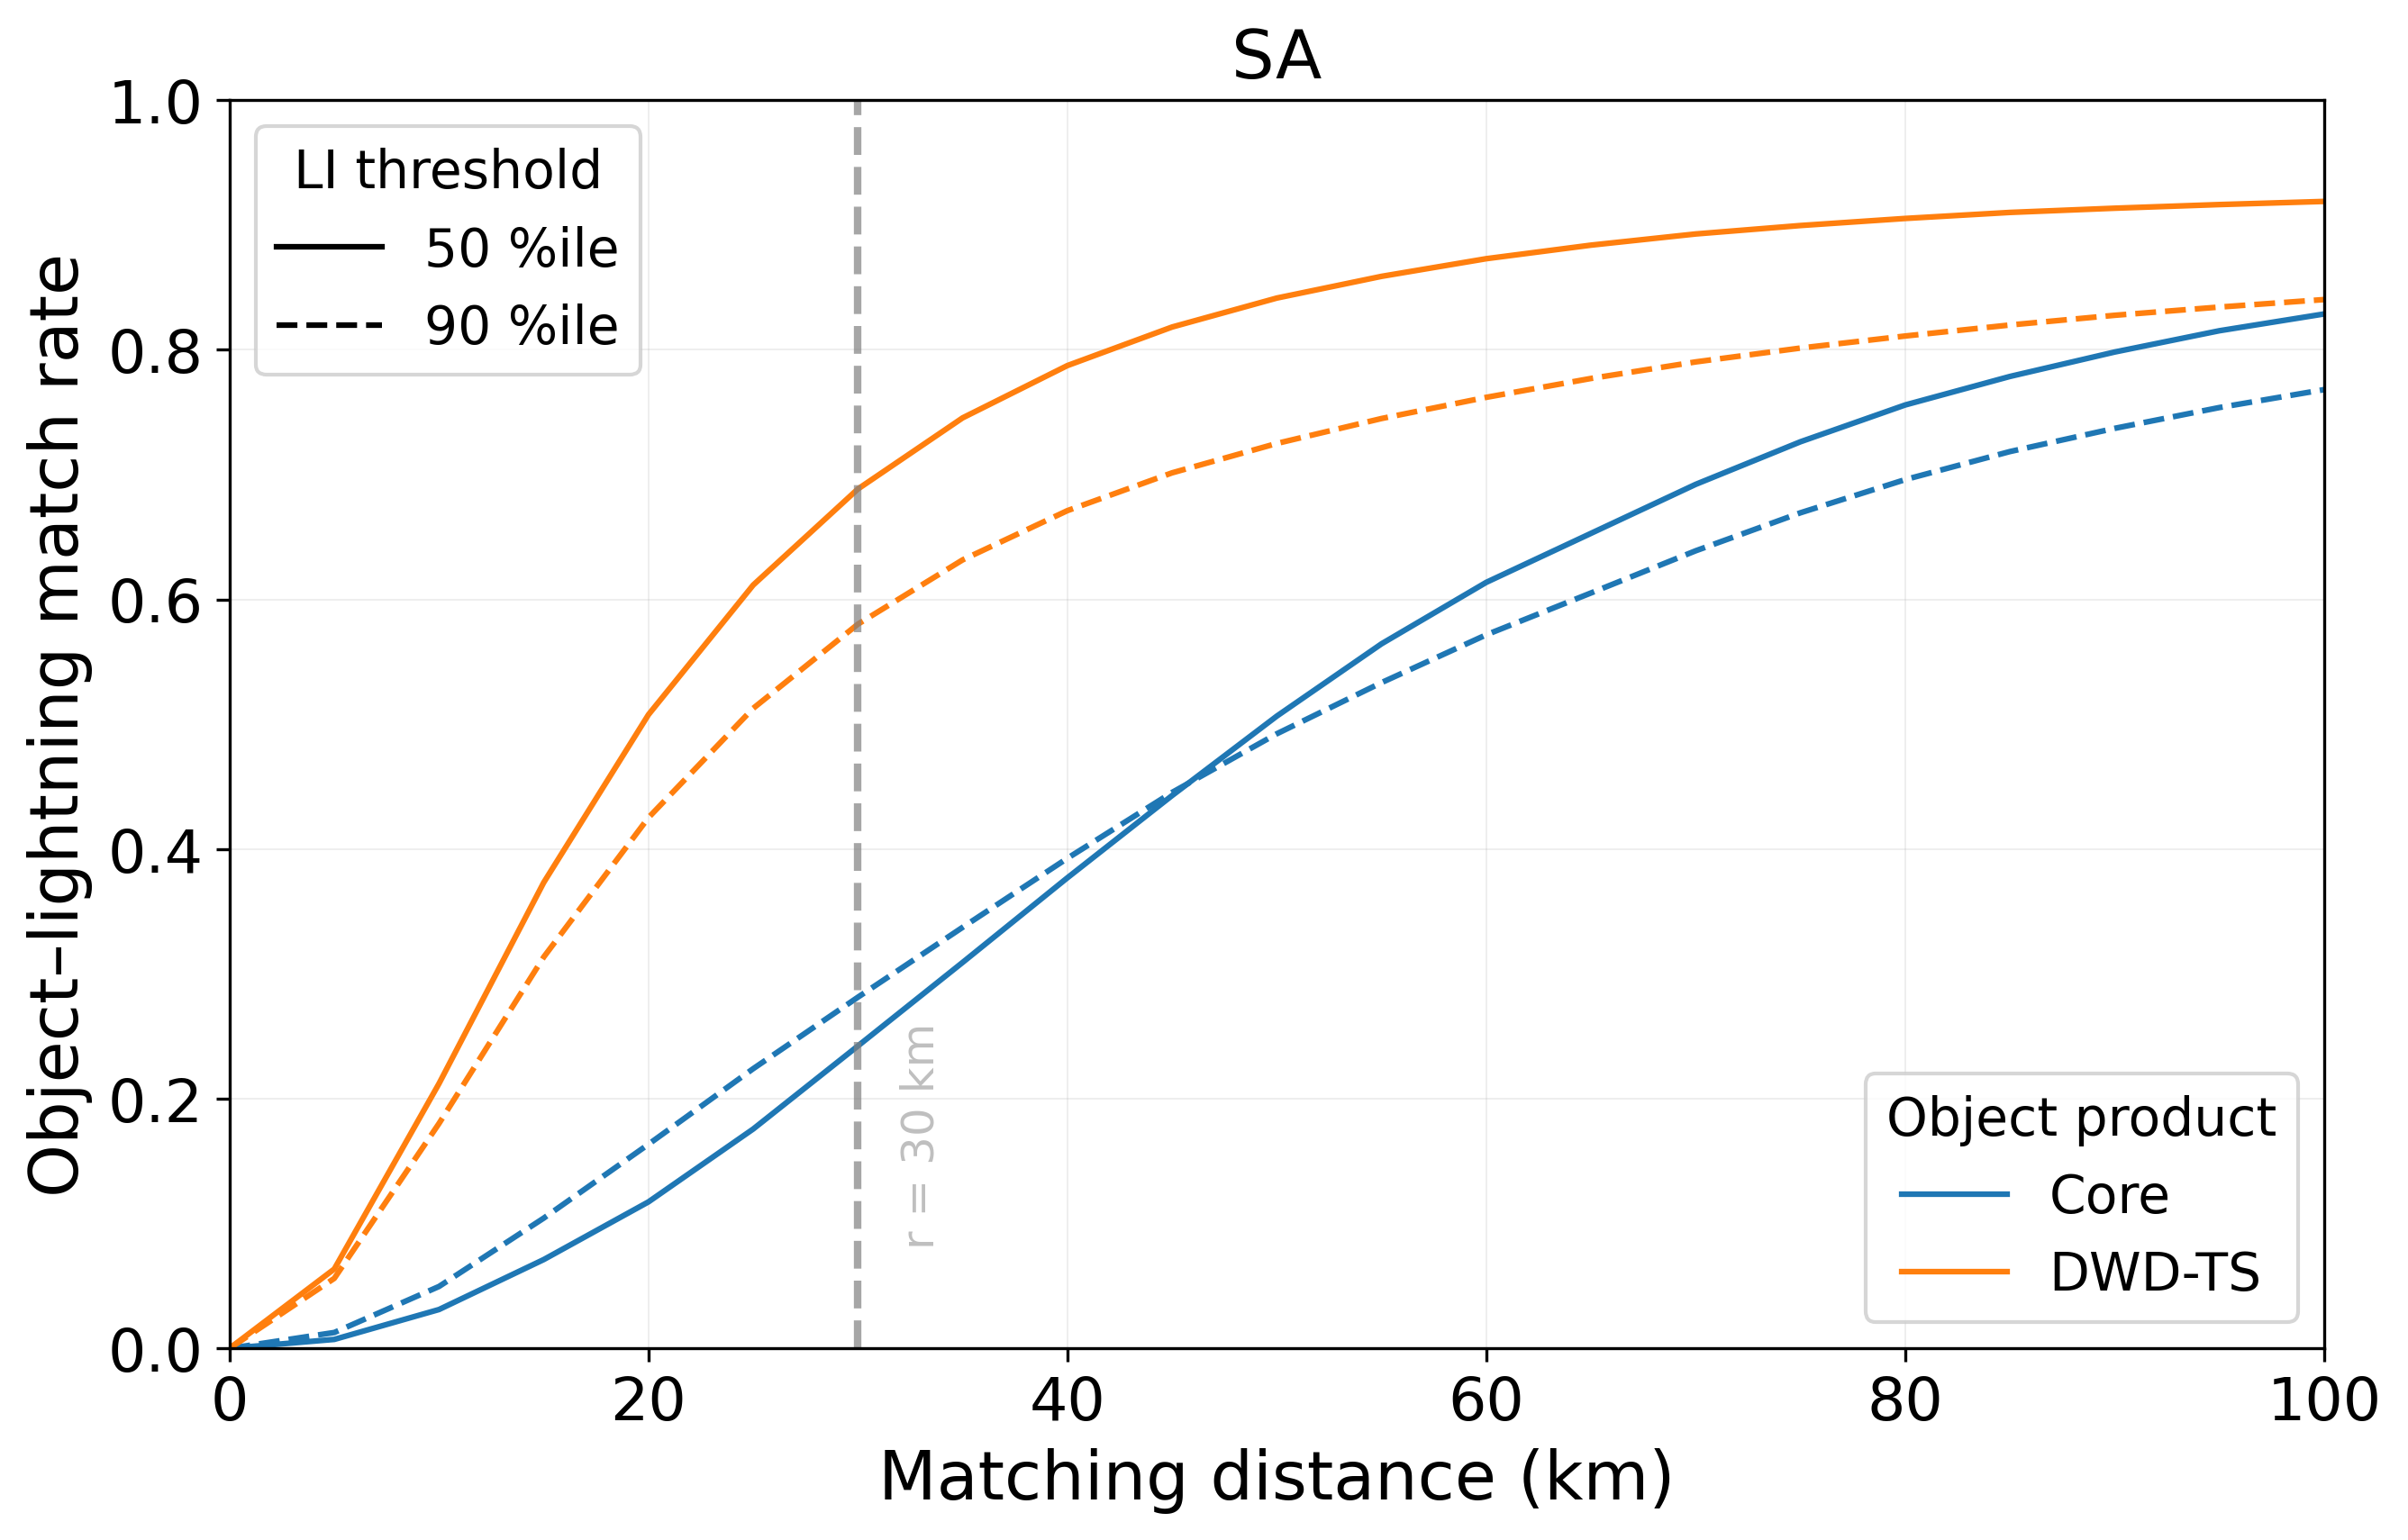

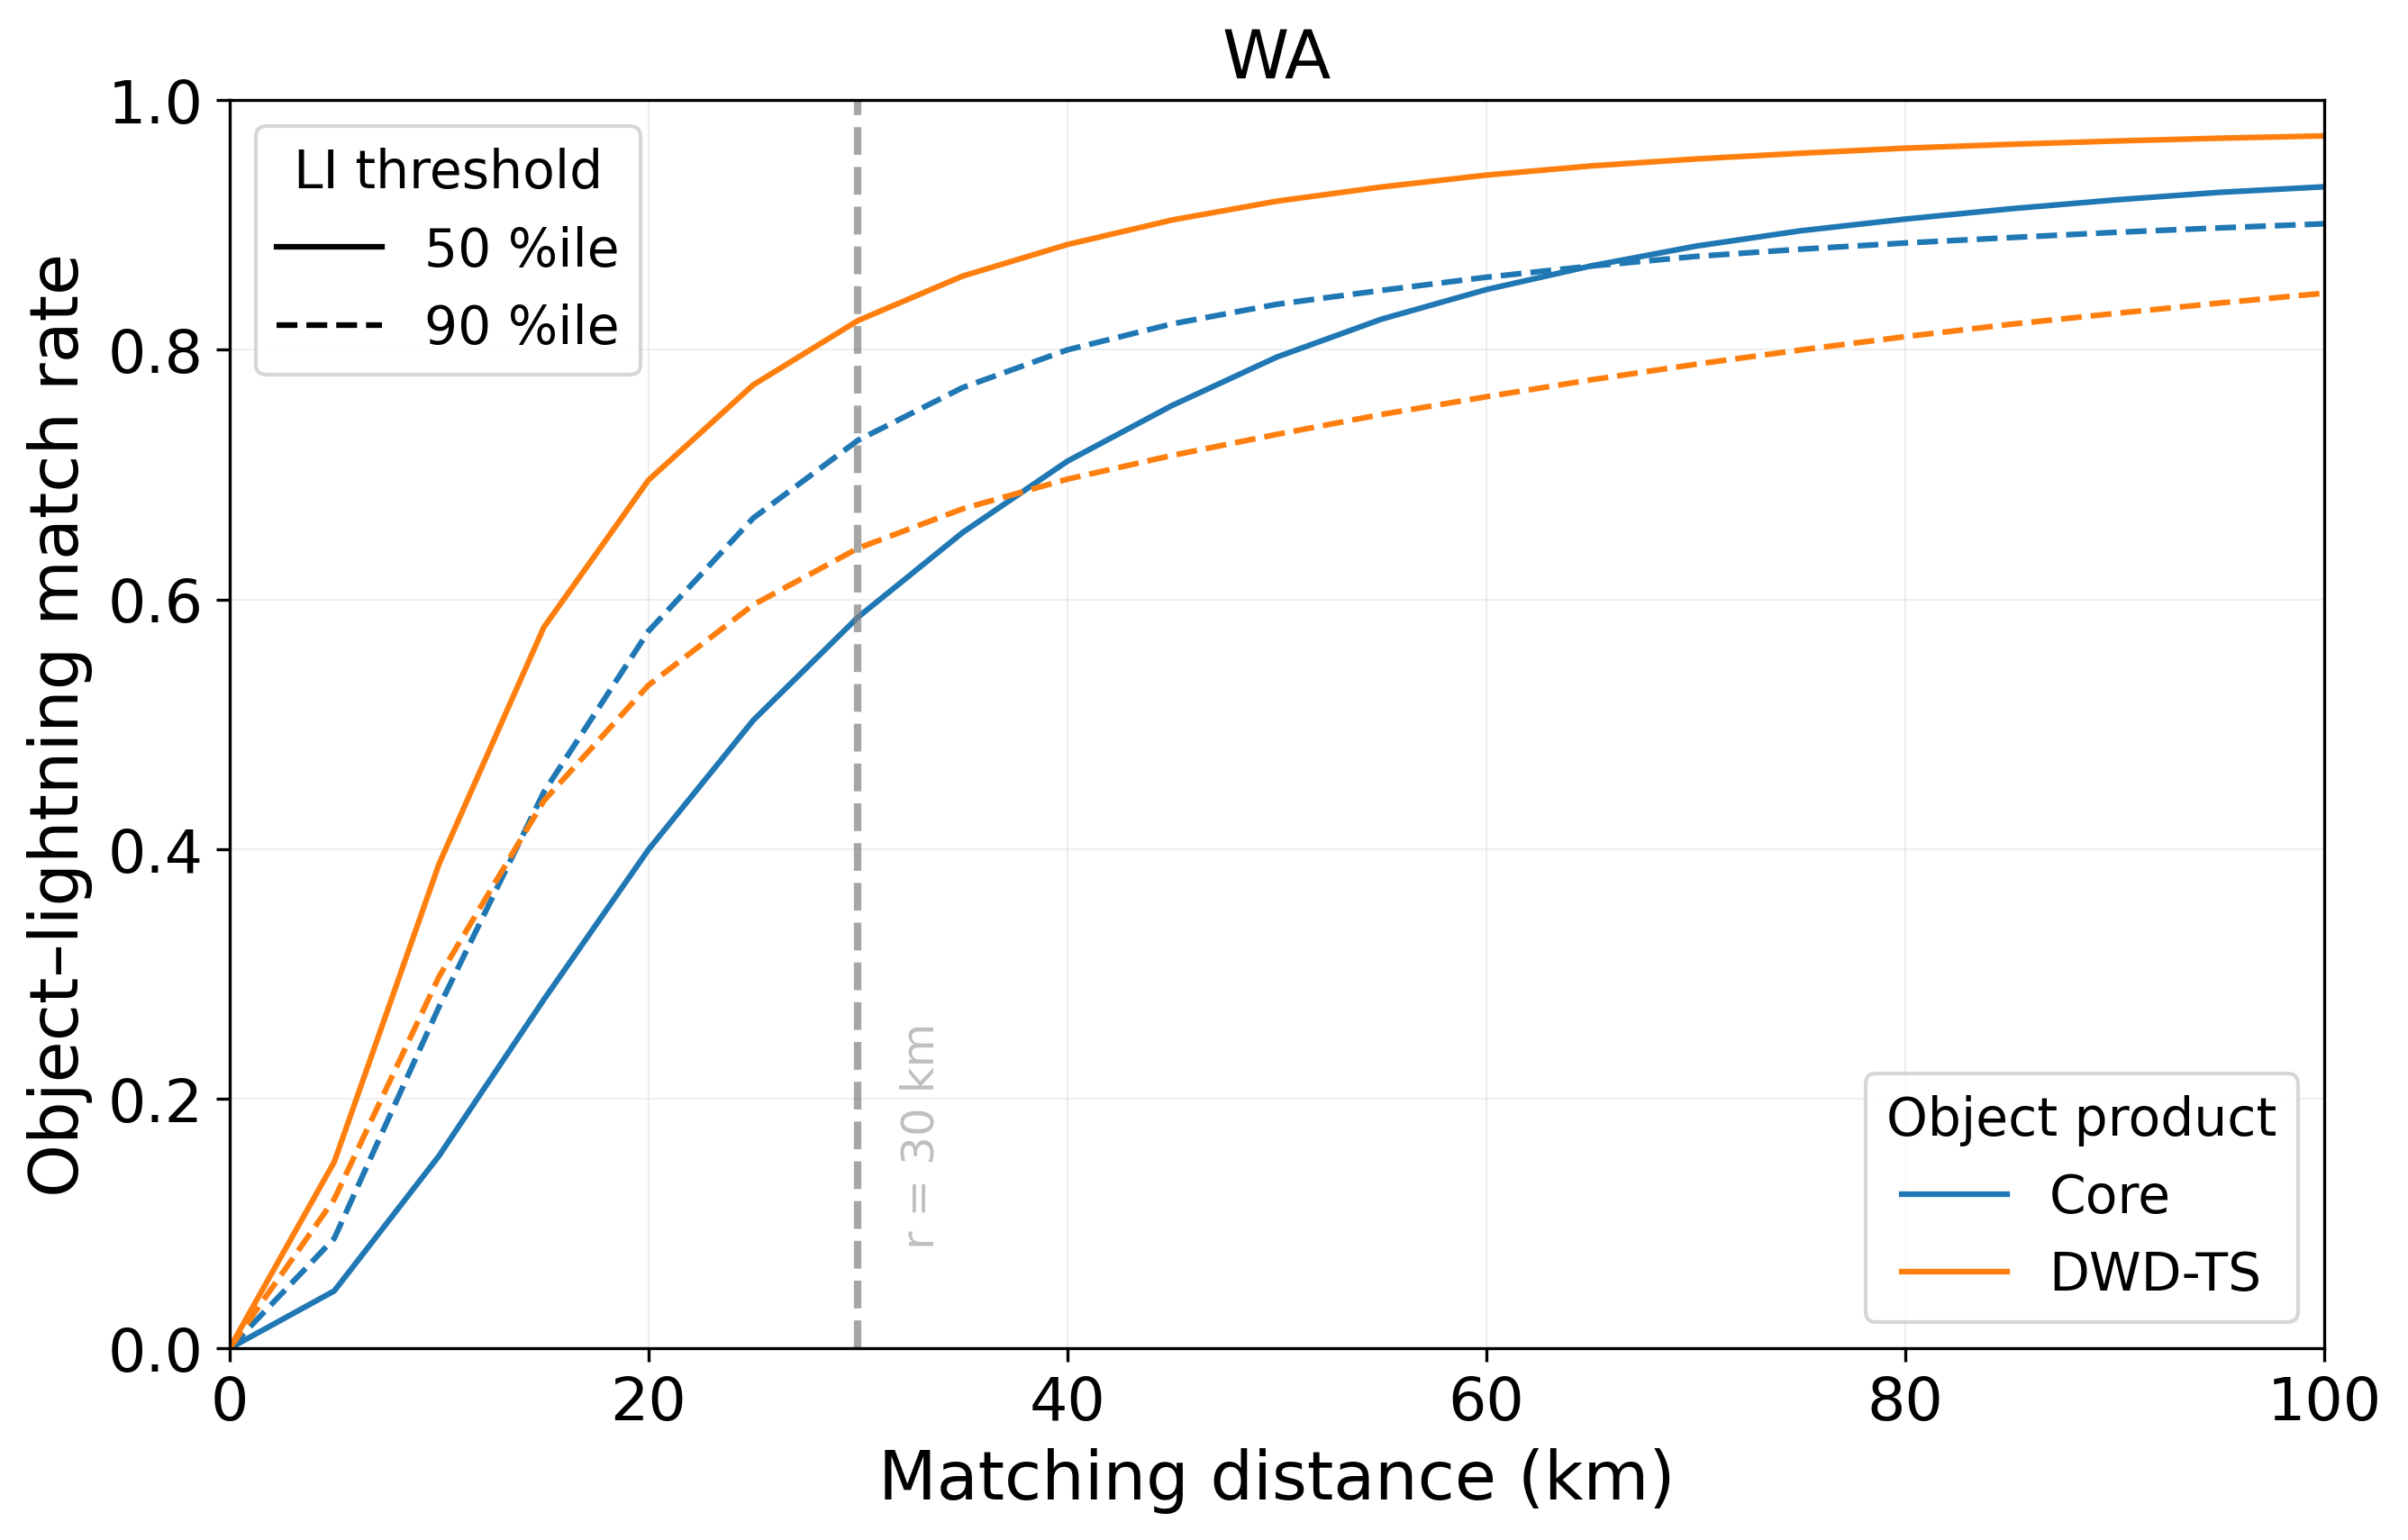

In [29]:
from matplotlib.lines import Line2D


radii = np.arange(0, 105, 5)

domains = ["CA", "EA", "SA", "WA"]
thresholds = [0.032, 1.056]

linestyles = {
    0.032: "-",
    1.056: "--",
}

threshold_labels = {
    0.032: "50 %ile",
    1.056: "90 %ile",
}


for domain in domains:

    plt.figure(figsize=(10, 6), dpi=300)

    # Plot Core for each LI percentile level
    for i, threshold in enumerate(thresholds):

        core_rates = [
            np.mean(distances_li[domain][threshold]["core"] <= r)
            for r in radii
        ]

        if i == 0:
            core_line, = plt.plot(
                radii,
                core_rates,
                linestyle=linestyles[threshold],
            )
            core_color = core_line.get_color()

        else:
            plt.plot(
                radii,
                core_rates,
                linestyle=linestyles[threshold],
                color=core_color,
            )

    # Plot DWD-TS for each LI percentile level
    for i, threshold in enumerate(thresholds):

        ts_rates = [
            np.mean(distances_li[domain][threshold]["ts"] <= r)
            for r in radii
        ]

        if i == 0:
            ts_line, = plt.plot(
                radii,
                ts_rates,
                linestyle=linestyles[threshold],
            )
            ts_color = ts_line.get_color()

        else:
            plt.plot(
                radii,
                ts_rates,
                linestyle=linestyles[threshold],
                color=ts_color,
            )

    # Legend for object products
    object_handles = [
        Line2D(
            [0], [0],
            color=core_color,
            linestyle="-",
            label="Core",
        ),
        Line2D(
            [0], [0],
            color=ts_color,
            linestyle="-",
            label="DWD-TS",
        ),
    ]

    object_legend = plt.legend(
        handles=object_handles,
        title="Object product",
        fontsize=14,
        title_fontsize=14,
        loc="lower right",
    )

    plt.gca().add_artist(object_legend)

    # Legend for LI thresholds
    percentile_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle=linestyles[threshold],
            label=threshold_labels[threshold],
        )
        for threshold in thresholds
    ]

    plt.legend(
        handles=percentile_handles,
        title="LI threshold",
        fontsize=14,
        title_fontsize=14,
        loc="upper left",
    )

    plt.xlabel("Matching distance (km)", fontsize=18)
    plt.ylabel("Object–lightning match rate", fontsize=18)

    plt.xlim(0, 100)
    plt.ylim(0, 1)

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.grid(True, linewidth=0.1)

    plt.axvline(
        30,
        color="grey",
        linestyle="--",
        linewidth=2,
        alpha=0.7,
    )

    plt.text(
        32,
        0.08,
        "r = 30 km",
        fontsize=12,
        color="grey",
        rotation=90,
        va="bottom",
        alpha=0.5,
    )

    plt.title(domain, fontsize=18)

    plt.show()

In [13]:
for threshold in [0.0, 0.032, 1.056]:
    print(f"\nThreshold: {threshold}")

    print(
        "Core objects:",
        len(
            core_li[
                (core_li["domain"] == "WA")
                & (core_li["threshold"] == threshold)
            ]
        )
    )

    print(
        "LI objects:",
        len(
            li_core[
                (li_core["domain"] == "WA")
                & (li_core["threshold"] == threshold)
            ]
        )
    )


Threshold: 0.0
Core objects: 60322
LI objects: 7681

Threshold: 0.032
Core objects: 60322
LI objects: 366682

Threshold: 1.056
Core objects: 60278
LI objects: 290898
